In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel("../data/Online Retail.xlsx/Online Retail.xlsx")

df.head()

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

In [ ]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Negative and zero values
print("\nNegative Quantity:", (df["Quantity"] < 0).sum())
print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("\nNegative UnitPrice:", (df["UnitPrice"] < 0).sum())
print("Zero UnitPrice:", (df["UnitPrice"] == 0).sum())

# Cancelled invoices
print("\nCancelled Invoices:", 
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

In [ ]:
# Inspect cancelled transactions
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled Transaction Samples:")
display(cancelled.head(10))

# Inspect negative quantities
negative_qty = df[df["Quantity"] < 0]

print("\nNegative Quantity Samples:")
display(negative_qty.head(10))

# Inspect zero and negative prices
unusual_prices = df[df["UnitPrice"] <= 0]

print("\nUnusual Price Samples:")
display(unusual_prices.head(10))

# Customer and invoice statistics
print("\nUnique Customers:", df["CustomerID"].nunique())
print("Unique Invoices:", df["InvoiceNo"].nunique())

print("\nTransaction Date Range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

In [ ]:
print("Zero Price Transactions:", (df["UnitPrice"] == 0).sum())

print("\nNegative Price Transactions:", (df["UnitPrice"] < 0).sum())

print("\nZero Price with CustomerID:",
      df[(df["UnitPrice"] == 0) & (df["CustomerID"].notna())].shape[0])

print("\nZero Price with Missing CustomerID:",
      df[(df["UnitPrice"] == 0) & (df["CustomerID"].isna())].shape[0])

In [ ]:
negative_prices = df[df["UnitPrice"] < 0]

display(negative_prices)

In [ ]:
print("Total Duplicate Rows:", df.duplicated().sum())

print("Rows with Missing CustomerID:", df["CustomerID"].isna().sum())

print("Duplicate Rows with Missing CustomerID:",
      df[df["CustomerID"].isna()].duplicated().sum())

print("Duplicate Rows with CustomerID:",
      df[df["CustomerID"].notna()].duplicated().sum())

In [ ]:
duplicates = df[df.duplicated(keep=False)]

display(duplicates.head(20))

In [ ]:
duplicate_groups = (
    df.groupby(
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"],
        dropna=False
    )
    .size()
    .reset_index(name="Occurrences")
)

display(
    duplicate_groups[duplicate_groups["Occurrences"] > 1].head(15)
)

### Data Quality Investigation — Findings

The initial data quality assessment identified the following issues:

1. **Missing Values**
   - CustomerID: 135,080 missing records (24.93%)
   - Description: 1,454 missing records.

2. **Duplicate Transactions**
   - 5,268 exact duplicate rows identified.
   - Duplicate records will be removed while preserving one occurrence.

3. **Cancelled Transactions**
   - 9,288 records have InvoiceNo starting with "C".
   - These represent cancellation or credit-note transactions and will be excluded from purchase-based RFM calculations.

4. **Negative Quantities**
   - 10,624 records contain negative quantities.
   - These will be investigated and excluded from positive purchase calculations.

5. **Zero Unit Prices**
   - 2,515 records have zero unit prices.
   - These will be excluded from revenue-based purchase analysis.

6. **Negative Unit Prices**
   - 2 records represent "Adjust bad debt" accounting entries.
   - These will be excluded from customer purchase analysis.

**Cleaning principle:** Preserve the original dataset and perform all cleaning operations on a separate working copy.

In [14]:
# Create a separate working copy
df_clean = df.copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

print("Original Dataset Shape:", df.shape)
print("After Removing Duplicates:", df_clean.shape)

print("Duplicate Rows Remaining:", df_clean.duplicated().sum())

Original Dataset Shape: (541909, 8)
After Removing Duplicates: (536641, 8)
Duplicate Rows Remaining: 0


In [15]:
# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Dataset Shape After Removing Cancellations:", df_clean.shape)

print("Cancelled Invoices Remaining:",
      df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())

Dataset Shape After Removing Cancellations: (527390, 8)
Cancelled Invoices Remaining: 0


In [16]:
# Remove negative quantity transactions
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

print("Dataset Shape After Removing Negative Quantities:", df_clean.shape)

print("Negative Quantities Remaining:",
      (df_clean["Quantity"] < 0).sum())

print("Zero Quantities Remaining:",
      (df_clean["Quantity"] == 0).sum())

Dataset Shape After Removing Negative Quantities: (526054, 8)
Negative Quantities Remaining: 0
Zero Quantities Remaining: 0


In [17]:
# Keep only transactions with positive unit prices
df_clean = df_clean[df_clean["UnitPrice"] > 0].copy()

print("Dataset Shape After Price Cleaning:", df_clean.shape)

print("Zero Prices Remaining:",
      (df_clean["UnitPrice"] == 0).sum())

print("Negative Prices Remaining:",
      (df_clean["UnitPrice"] < 0).sum())

Dataset Shape After Price Cleaning: (524878, 8)
Zero Prices Remaining: 0
Negative Prices Remaining: 0


In [18]:
# Remove transactions with missing CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"]).copy()

print("Dataset Shape After Removing Missing CustomerIDs:", df_clean.shape)

print("Missing CustomerIDs Remaining:",
      df_clean["CustomerID"].isna().sum())

print("Unique Customers Remaining:",
      df_clean["CustomerID"].nunique())

Dataset Shape After Removing Missing CustomerIDs: (392692, 8)
Missing CustomerIDs Remaining: 0
Unique Customers Remaining: 4338


In [ ]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nNegative Quantities:", (df_clean["Quantity"] < 0).sum())

print("Non-Positive Prices:", (df_clean["UnitPrice"] <= 0).sum())

print("Cancelled Invoices:",
      df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())

print("\nUnique Customers:", df_clean["CustomerID"].nunique())

print("Unique Invoices:", df_clean["InvoiceNo"].nunique())

In [ ]:
# Calculate total revenue per transaction
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print(df_clean[
    ["Quantity", "UnitPrice", "TotalPrice"]
].head(10))

print("\nRevenue Summary:")
print(df_clean["TotalPrice"].describe())

In [21]:
# Calculate total business revenue
total_revenue = df_clean["TotalPrice"].sum()

print("Total Business Revenue: £{:,.2f}".format(total_revenue))

print("Average Transaction Revenue: £{:.2f}".format(
    df_clean["TotalPrice"].mean()
))

print("Median Transaction Revenue: £{:.2f}".format(
    df_clean["TotalPrice"].median()
))

Total Business Revenue: £8,887,208.89
Average Transaction Revenue: £22.63
Median Transaction Revenue: £12.45


In [ ]:
# Investigate the 10 highest-value purchase records

top_transactions = df_clean.sort_values(
    by="TotalPrice",
    ascending=False
)

top_transactions[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "TotalPrice",
     "CustomerID", "InvoiceDate", "Country"]
].head(10)

In [ ]:
# Investigate suspicious transactions in original dataset

df[
    df["InvoiceNo"].astype(str).str.contains(
        "581483|581484|541431|541433",
        regex=True
    )
][[
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "UnitPrice",
    "CustomerID",
    "InvoiceDate"
]].sort_values("InvoiceDate")

In [24]:
# Remove original transactions that were later cancelled

df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).isin(
        ["541431", "581483"]
    )
].copy()

print("Updated Dataset Shape:", df_clean.shape)
print("Updated Revenue: £{:,.2f}".format(
    df_clean["TotalPrice"].sum()
))

Updated Dataset Shape: (392690, 9)
Updated Revenue: £8,641,555.69


In [25]:
# Check customer and transaction statistics

print("Unique Customers:", df_clean["CustomerID"].nunique())
print("Unique Invoices:", df_clean["InvoiceNo"].nunique())
print("Date Range:")
print(df_clean["InvoiceDate"].min())
print(df_clean["InvoiceDate"].max())

Unique Customers: 4337
Unique Invoices: 18530
Date Range:
2010-12-01 08:26:00
2011-12-09 12:50:00


In [26]:
# Define reference date for RFM analysis

reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [27]:
# Calculate RFM metrics for each customer

rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalPrice": "sum"
})

# Rename columns
rfm.rename(columns={
    "InvoiceDate": "Recency",
    "InvoiceNo": "Frequency",
    "TotalPrice": "Monetary"
}, inplace=True)

# Display first 10 customers
rfm.head(10)

C:\Users\Person-AL-Computer\AppData\Local\Temp\ipykernel_15200\851057809.py:10: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  rfm.rename(columns={


,Recency,Frequency,Monetary
CustomerID,,,
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40
12356.0,23,3,2811.43


In [28]:
# RFM Statistical Summary

print(rfm.describe().round(2))

       Recency  Frequency   Monetary
count  4337.00    4337.00    4337.00
mean     92.53       4.27    1992.52
std      99.97       7.70    8547.58
min       1.00       1.00       2.90
25%      18.00       1.00     306.45
50%      51.00       2.00     668.43
75%     142.00       5.00    1657.28
max     374.00     209.00  280206.02


In [29]:
# Calculate RFM Scores (1 to 5)

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12347.0,2,7,4310.00,5,5,5
12348.0,75,4,1797.24,2,4,4
12349.0,19,1,1757.55,4,1,4
12350.0,310,1,334.40,1,1,2
12352.0,36,8,2506.04,3,5,5
12353.0,204,1,89.00,1,1,1
12354.0,232,1,1079.40,1,1,4
12355.0,214,1,459.40,1,1,2
12356.0,23,3,2811.43,4,3,5


In [30]:
# Combine RFM scores

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

# Calculate total RFM score
rfm["RFM_Total"] = (
    rfm["R_Score"].astype(int) +
    rfm["F_Score"].astype(int) +
    rfm["M_Score"].astype(int)
)

# Display results
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
CustomerID,,,,,,,,
12347.0,2,7,4310.00,5,5,5,555,15
12348.0,75,4,1797.24,2,4,4,244,10
12349.0,19,1,1757.55,4,1,4,414,9
12350.0,310,1,334.40,1,1,2,112,4
12352.0,36,8,2506.04,3,5,5,355,13
12353.0,204,1,89.00,1,1,1,111,3
12354.0,232,1,1079.40,1,1,4,114,6
12355.0,214,1,459.40,1,1,2,112,4
12356.0,23,3,2811.43,4,3,5,435,12


In [31]:
# Distribution of RFM Total Scores

print("RFM Total Score Distribution:")
print(rfm["RFM_Total"].value_counts().sort_index())

print("\nRFM Score Summary:")
print(rfm["RFM_Total"].describe())

RFM Total Score Distribution:
RFM_Total
3     184
4     363
5     338
6     429
7     378
8     381
9     324
10    349
11    345
12    318
13    285
14    296
15    347
Name: count, dtype: int64

RFM Score Summary:
count    4337.000000
mean        9.000000
std         3.590681
min         3.000000
25%         6.000000
50%         9.000000
75%        12.000000
max        15.000000
Name: RFM_Total, dtype: float64


In [32]:
# Assign Customer Segments

def segment_customer(row):

    r = int(row["R_Score"])
    f = int(row["F_Score"])
    m = int(row["M_Score"])

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif r >= 4 and f <= 2:
        return "Recent Customers"

    elif r <= 2 and f >= 3:
        return "At Risk"

    else:
        return "Hibernating"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

# Display first 10 customers
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Customer_Segment
CustomerID,,,,,,,,,
12347.0,2,7,4310.00,5,5,5,555,15,Champions
12348.0,75,4,1797.24,2,4,4,244,10,At Risk
12349.0,19,1,1757.55,4,1,4,414,9,Recent Customers
12350.0,310,1,334.40,1,1,2,112,4,Hibernating
12352.0,36,8,2506.04,3,5,5,355,13,Loyal Customers
12353.0,204,1,89.00,1,1,1,111,3,Hibernating
12354.0,232,1,1079.40,1,1,4,114,6,Hibernating
12355.0,214,1,459.40,1,1,2,112,4,Hibernating
12356.0,23,3,2811.43,4,3,5,435,12,Potential Loyalists


In [33]:
# Customer count by segment

segment_counts = (
    rfm["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_counts.columns = [
    "Customer_Segment",
    "Customer_Count"
]

segment_counts["Percentage"] = (
    segment_counts["Customer_Count"] /
    len(rfm) * 100
).round(2)

print(segment_counts)

      Customer_Segment  Customer_Count  Percentage
0          Hibernating            1613       37.19
1            Champions             944       21.77
2              At Risk             661       15.24
3      Loyal Customers             506       11.67
4  Potential Loyalists             475       10.95
5     Recent Customers             138        3.18


In [34]:
# Segment-wise revenue analysis

segment_revenue = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customer_Count=("Monetary", "count"),
        Total_Revenue=("Monetary", "sum"),
        Average_Spending=("Monetary", "mean")
    )
    .sort_values(
        by="Total_Revenue",
        ascending=False
    )
)

segment_revenue["Revenue_Percentage"] = (
    segment_revenue["Total_Revenue"] /
    segment_revenue["Total_Revenue"].sum() * 100
).round(2)

print(segment_revenue.round(2))

                     Customer_Count  Total_Revenue  Average_Spending  \
Customer_Segment                                                       
Champions                       944     5739857.14           6080.36   
Loyal Customers                 506      925718.73           1829.48   
At Risk                         661      823912.44           1246.46   
Hibernating                    1613      773919.21            479.80   
Potential Loyalists             475      327485.50            689.44   
Recent Customers                138       50662.67            367.12   

                     Revenue_Percentage  
Customer_Segment                         
Champions                         66.42  
Loyal Customers                   10.71  
At Risk                            9.53  
Hibernating                        8.96  
Potential Loyalists                3.79  
Recent Customers                   0.59  


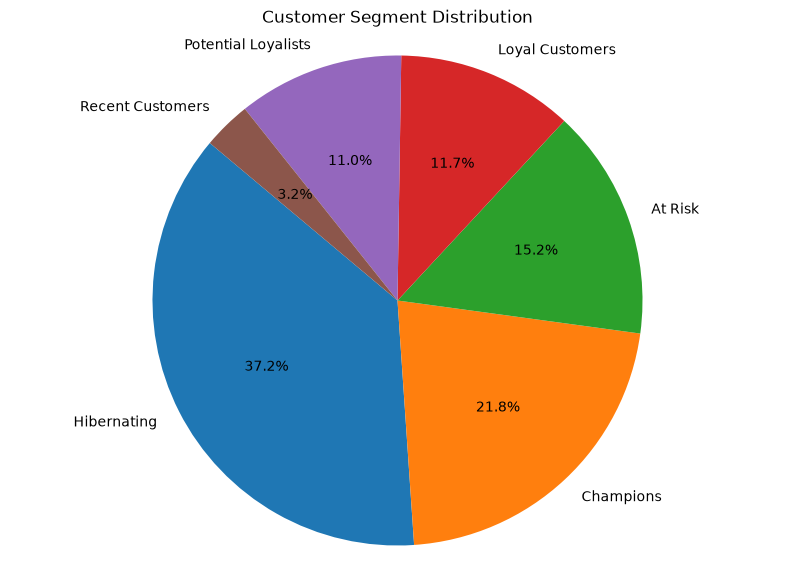

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.pie(
    segment_counts["Customer_Count"],
    labels=segment_counts["Customer_Segment"],
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Customer Segment Distribution")
plt.axis("equal")

plt.savefig(
    "../images/customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

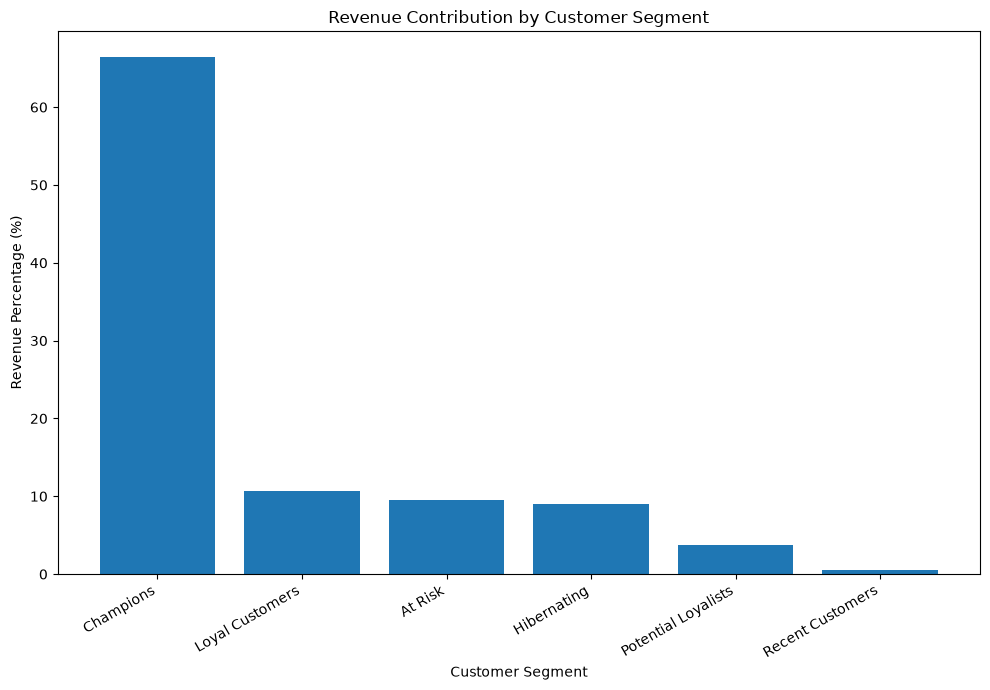

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.bar(
    segment_revenue.index,
    segment_revenue["Revenue_Percentage"]
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Percentage (%)")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    "../images/segment_revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## K-Means Customer Clustering — Machine Learning

### Objective
The objective of this phase is to apply the K-Means clustering algorithm to identify customer groups based on their purchasing behaviour.

Unlike RFM rule-based segmentation, K-Means is an unsupervised machine learning algorithm that discovers patterns and groups customers based on similarities in their data.

### Key Activities
- Prepare customer-level RFM features for clustering.
- Apply feature scaling to normalize the data.
- Determine the optimal number of clusters using the Elbow Method and Silhouette Score.
- Train the K-Means clustering model.
- Visualize customer clusters using PCA.
- Analyze cluster characteristics and derive actionable business insights.

### Expected Outcome
Develop a machine learning-based customer segmentation model that identifies distinct customer groups and supports data-driven marketing and business strategies.

In [38]:
# Prepare features for K-Means clustering

X = rfm[[
    "Recency",
    "Frequency",
    "Monetary"
]].copy()

print("Clustering Dataset Shape:", X.shape)

print("\nFirst 5 Records:")
print(X.head())

Clustering Dataset Shape: (4337, 3)

First 5 Records:
            Recency  Frequency  Monetary
CustomerID                              
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
12352.0          36          8   2506.04


In [39]:
# Apply log transformation to reduce skewness

X_log = np.log1p(X)

print("Log Transformed Data:")
print(X_log.head())

print("\nSkewness Before Transformation:")
print(X.skew())

print("\nSkewness After Transformation:")
print(X_log.skew())

Log Transformed Data:
             Recency  Frequency  Monetary
CustomerID                               
12347.0     1.098612   2.079442  8.368925
12348.0     4.330733   1.609438  7.494564
12349.0     2.995732   0.693147  7.472245
12350.0     5.739793   0.693147  5.815324
12352.0     3.610918   2.197225  7.826858

Skewness Before Transformation:
Recency       1.245834
Frequency    12.065806
Monetary     20.629800
dtype: float64

Skewness After Transformation:
Recency     -0.378777
Frequency    1.208328
Monetary     0.359874
dtype: float64


In [40]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Scale the transformed features
X_scaled = scaler.fit_transform(X_log)

# Convert scaled array back to DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X_log.columns,
    index=X_log.index
)

print("Scaled Dataset:")
print(X_scaled.head())

print("\nFeature Means:")
print(X_scaled.mean().round(3))

print("\nFeature Standard Deviations:")
print(X_scaled.std().round(3))

Scaled Dataset:
             Recency  Frequency  Monetary
CustomerID                               
12347.0    -2.040458   1.074234  1.420050
12348.0     0.372874   0.386182  0.724026
12349.0    -0.623933  -0.955202  0.706259
12350.0     1.424978  -0.955202 -0.612711
12352.0    -0.164592   1.246660  0.988544

Feature Means:
Recency     -0.0
Frequency    0.0
Monetary    -0.0
dtype: float64

Feature Standard Deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


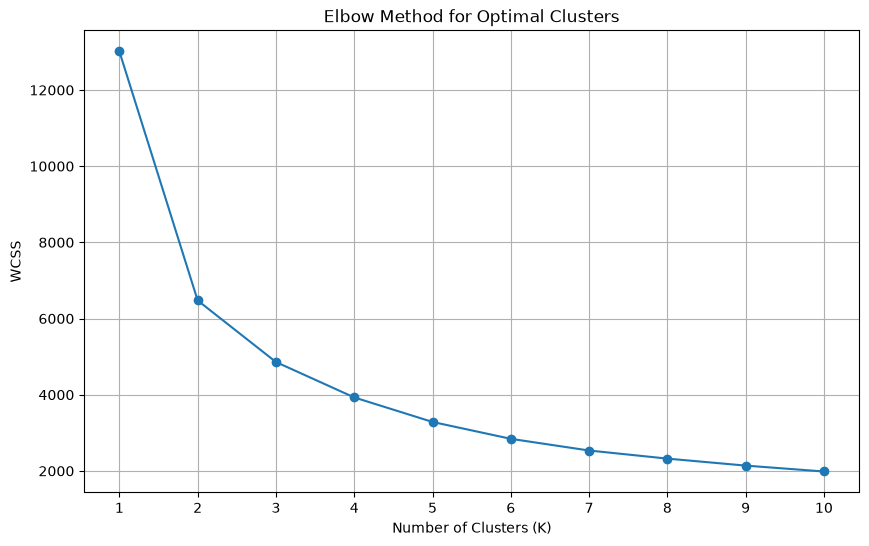

In [41]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate WCSS for different cluster counts
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)

plt.savefig(
    "../images/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4329
K = 3, Silhouette Score = 0.3359
K = 4, Silhouette Score = 0.3372
K = 5, Silhouette Score = 0.3165
K = 6, Silhouette Score = 0.3136
K = 7, Silhouette Score = 0.3100
K = 8, Silhouette Score = 0.3015
K = 9, Silhouette Score = 0.2815
K = 10, Silhouette Score = 0.2776


In [43]:
# Train final candidate K-Means model

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign cluster labels to customers
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

# Check cluster sizes
cluster_counts = rfm["Cluster"].value_counts().sort_index()

print("Customer Count in Each Cluster:")
print(cluster_counts)

print("\nCluster Percentages:")
print((cluster_counts / len(rfm) * 100).round(2))

Customer Count in Each Cluster:
Cluster
0    1615
1     840
2     707
3    1175
Name: count, dtype: int64

Cluster Percentages:
Cluster
0    37.24
1    19.37
2    16.30
3    27.09
Name: count, dtype: float64


In [44]:
# Analyze customer behaviour in each cluster

cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print("K-Means Cluster Profiles:")
print(cluster_profile)

K-Means Cluster Profiles:
         Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
Cluster                                                          
0                  1615       183.14           1.32        348.72
1                   840        18.37           2.12        539.44
2                   707        12.09          13.82       7894.48
3                  1175        69.40           4.12       1739.45


In [45]:
# Assign business-friendly names to clusters

cluster_names = {
    0: "Hibernating Customers",
    1: "Recent Low-Spenders",
    2: "Champions",
    3: "Loyal Customers"
}

rfm["Cluster_Name"] = rfm["Cluster"].map(cluster_names)

print(rfm[[
    "Recency",
    "Frequency",
    "Monetary",
    "Cluster",
    "Cluster_Name"
]].head(10))

            Recency  Frequency  Monetary  Cluster           Cluster_Name
CustomerID                                                              
12347.0           2          7   4310.00        2              Champions
12348.0          75          4   1797.24        3        Loyal Customers
12349.0          19          1   1757.55        1    Recent Low-Spenders
12350.0         310          1    334.40        0  Hibernating Customers
12352.0          36          8   2506.04        3        Loyal Customers
12353.0         204          1     89.00        0  Hibernating Customers
12354.0         232          1   1079.40        0  Hibernating Customers
12355.0         214          1    459.40        0  Hibernating Customers
12356.0          23          3   2811.43        3        Loyal Customers
12357.0          33          1   6207.67        3        Loyal Customers


In [46]:
from sklearn.decomposition import PCA

# Reduce 3 dimensions to 2 dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame for visualization
pca_df = pd.DataFrame(
    X_pca,
    columns=["PCA1", "PCA2"],
    index=rfm.index
)

# Add cluster labels
pca_df["Cluster"] = rfm["Cluster"]

print("PCA Dataset:")
print(pca_df.head())

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

print(
    "\nTotal Variance Explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA Dataset:
                PCA1      PCA2  Cluster
CustomerID                             
12347.0     2.555268 -0.804403        2
12348.0     0.480231  0.748875        3
12349.0     0.150271 -0.458764        1
12350.0    -1.684968  0.680960        0
12352.0     1.444895  0.638595        3

Explained Variance Ratio:
[0.752  0.1878]

Total Variance Explained: 93.98 %


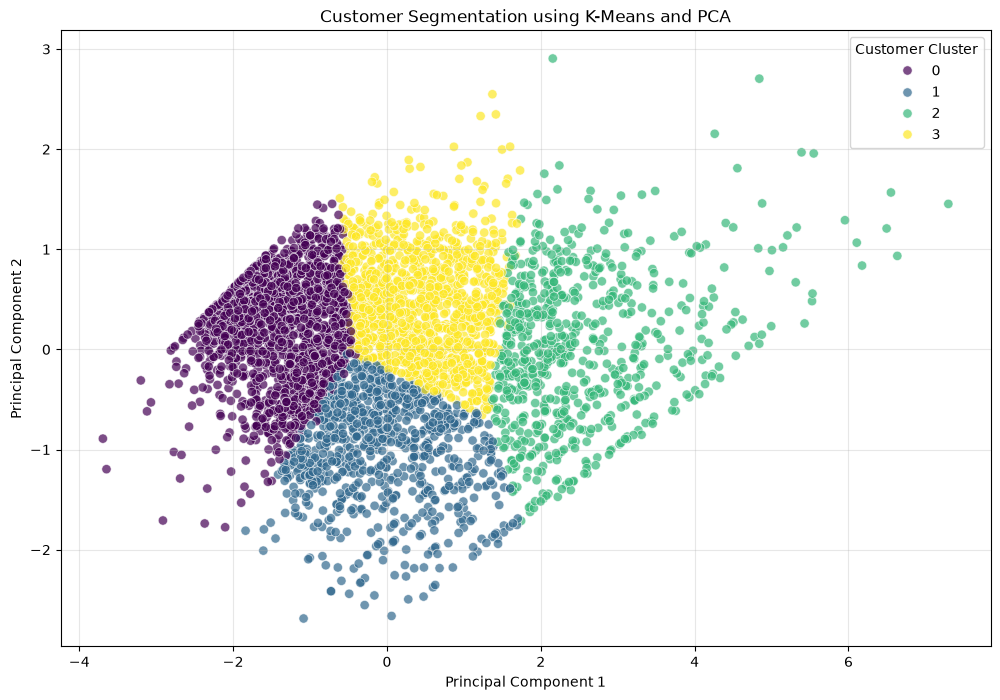

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="viridis",
    s=45,
    alpha=0.7
)

plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.grid(alpha=0.3)

plt.savefig(
    "../images/customer_clusters_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Customer Lifetime Value (CLV) Analysis

### CLV Calculation Methodology

In this project, a historical customer value approach will be used to evaluate customer contributions based on their purchasing behaviour.

**Key Metrics:**

- **Total Customer Revenue:** Total amount spent by each customer.
- **Purchase Frequency:** Number of unique invoices generated by each customer.
- **Average Order Value (AOV):** Average revenue generated per invoice.
- **Average Customer Value:** Average historical revenue contribution per customer.

**CLV Approach:**

Since the dataset covers approximately one year of historical transactions, customer lifetime value will be estimated using historical purchasing data rather than a predictive lifetime model.

**Business Purpose:**

- Identify high-value customers.
- Compare customer value across K-Means segments.
- Support customer retention and marketing decisions.
- Identify opportunities to increase customer spending.

In [48]:
# Calculate Customer-Level Value Metrics

customer_clv = rfm[[
    "Recency",
    "Frequency",
    "Monetary",
    "Cluster_Name"
]].copy()

# Calculate Average Order Value
customer_clv["Average_Order_Value"] = (
    customer_clv["Monetary"] /
    customer_clv["Frequency"]
)

print("Customer CLV Dataset:")
print(customer_clv.head(10))

print("\nOverall Customer Metrics:")
print(customer_clv[[
    "Frequency",
    "Monetary",
    "Average_Order_Value"
]].describe().round(2))

Customer CLV Dataset:
            Recency  Frequency  Monetary           Cluster_Name  \
CustomerID                                                        
12347.0           2          7   4310.00              Champions   
12348.0          75          4   1797.24        Loyal Customers   
12349.0          19          1   1757.55    Recent Low-Spenders   
12350.0         310          1    334.40  Hibernating Customers   
12352.0          36          8   2506.04        Loyal Customers   
12353.0         204          1     89.00  Hibernating Customers   
12354.0         232          1   1079.40  Hibernating Customers   
12355.0         214          1    459.40  Hibernating Customers   
12356.0          23          3   2811.43        Loyal Customers   
12357.0          33          1   6207.67        Loyal Customers   

            Average_Order_Value  
CustomerID                       
12347.0              615.714286  
12348.0              449.310000  
12349.0             1757.550000  
123

In [49]:
# Analyze Customer Value by Segment

clv_by_segment = customer_clv.groupby("Cluster_Name").agg(
    Customer_Count=("Monetary", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_CLV=("Monetary", "mean"),
    Average_Order_Value=("Average_Order_Value", "mean"),
    Average_Frequency=("Frequency", "mean")
).round(2)

# Calculate revenue contribution
clv_by_segment["Revenue_Percentage"] = (
    clv_by_segment["Total_Revenue"] /
    clv_by_segment["Total_Revenue"].sum() * 100
).round(2)

clv_by_segment = clv_by_segment.sort_values(
    by="Total_Revenue",
    ascending=False
)

print("Customer Lifetime Value by Segment:")
print(clv_by_segment)

Customer Lifetime Value by Segment:
                       Customer_Count  Total_Revenue  Average_CLV  \
Cluster_Name                                                        
Champions                         707     5581394.12      7894.48   
Loyal Customers                  1175     2043852.49      1739.45   
Hibernating Customers            1615      563181.56       348.72   
Recent Low-Spenders               840      453127.52       539.44   

                       Average_Order_Value  Average_Frequency  \
Cluster_Name                                                    
Champions                           505.93              13.82   
Loyal Customers                     504.71               4.12   
Hibernating Customers               288.21               1.32   
Recent Low-Spenders                 278.76               2.12   

                       Revenue_Percentage  
Cluster_Name                               
Champions                           64.59  
Loyal Customers           

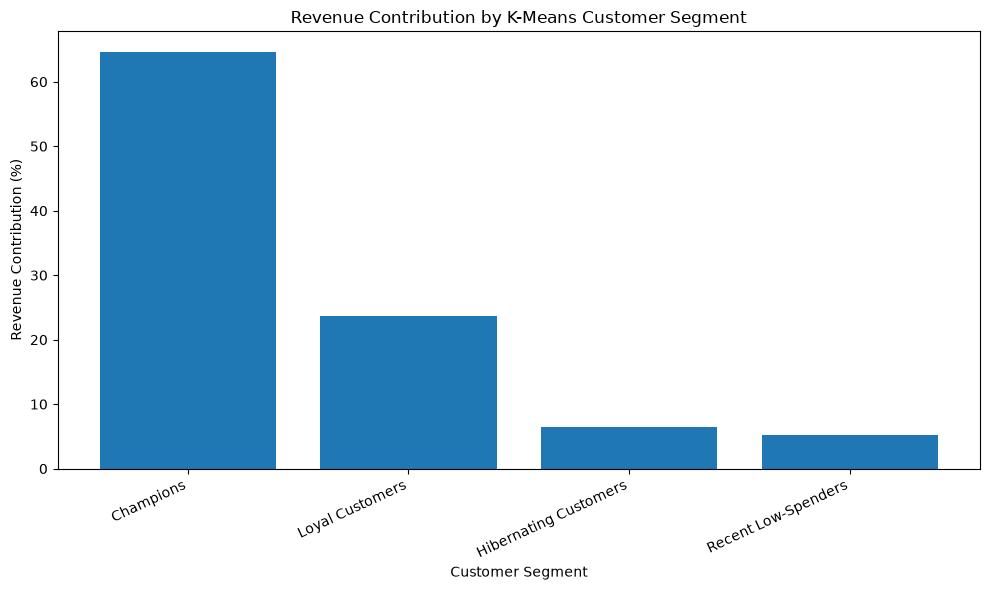

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    clv_by_segment.index,
    clv_by_segment["Revenue_Percentage"]
)

plt.title("Revenue Contribution by K-Means Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.savefig(
    "../images/clv_revenue_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### CLV Analysis — Key Business Insights

**1. Champions — Highest Value Segment**

Champions represent 16.30% of customers but contribute 64.59% of total revenue. These customers demonstrate strong purchasing activity and should be prioritized for customer retention.

**2. Loyal Customers — Growth Opportunity**

Loyal Customers contribute 23.65% of total revenue. Targeted loyalty programs and personalized offers can encourage them to become Champions.

**3. Hibernating Customers — Reactivation Opportunity**

Hibernating Customers represent 37.24% of the customer base but contribute only 6.52% of revenue. Win-back campaigns may help reactivate these customers.

**4. Recent Low-Spenders — Engagement Opportunity**

Recent Low-Spenders contribute 5.24% of revenue. Personalized recommendations and repeat-purchase incentives can help increase their purchasing frequency.

**Overall Conclusion:**

The analysis reveals that revenue is heavily concentrated among Champions. Businesses should prioritize retaining high-value customers while developing targeted strategies to reactivate inactive customers and increase the value of emerging customer segments.

In [51]:
rfm.to_csv("../data/customer_rfm.csv")